# Indian Flight Fare Analysis and Prediction

**Author:** MK NANDANA

**Description:** End-to-end Exploratory Data Analysis (EDA) on Indian domestic flight fare data to understand pricing patterns based on airlines, routes, booking window, flight duration, stops, departure time, and travel class.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (8,5)
plt.rcParams["figure.dpi"] = 100

#Section A – Data acquisition, inspection and preprocessing
Objective: Understand the structure, quality and reliability of the data.

##Question 1
###Download the dataset from Kaggle and load it into a Pandas DataFrame. Display the first 10 and last 10 records.

In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/MahishaG/Flight-Price-Prediction/main/Clean_Dataset.csv"

df = pd.read_csv(url)

df.head()

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


## Question 2

**Find the number of rows and columns. What does one row represent in this dataset?**

In [ ]:
print("Shape of Dataset:", df.shape)

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nEach row represents one flight ticket record with its details such as airline, source city, destination city, duration, class, days left before departure, and ticket price.")

Shape of Dataset: (300153, 11)

Number of Rows: 300153
Number of Columns: 11

Each row represents one flight ticket record with its details such as airline, source city, destination city, duration, class, days left before departure, and ticket price.


## Question 3

**Display the column names, data types and non-null counts using `info()`. Which columns are numerical, categorical and temporal?**

In [ ]:
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

numerical = df.select_dtypes(include=np.number).columns.tolist()
categorical = df.select_dtypes(include="object").columns.tolist()

print("\nNumerical Columns:")
print(numerical)

print("\nCategorical Columns:")
print(categorical)

print("\nTemporal Columns:")
print(["departure_time", "arrival_time"])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  object 
 1   flight            300153 non-null  object 
 2   source_city       300153 non-null  object 
 3   departure_time    300153 non-null  object 
 4   stops             300153 non-null  object 
 5   arrival_time      300153 non-null  object 
 6   destination_city  300153 non-null  object 
 7   class             300153 non-null  object 
 8   duration          300153 non-null  float64
 9   days_left         300153 non-null  int64  
 10  price             300153 non-null  int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 25.2+ MB

Column Names:
['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price']

Numerical Columns:
['duration', 'days_left'

## Question 4

**Calculate the memory consumption of the DataFrame. Can you reduce memory usage by changing suitable data types?**

In [ ]:
print("Memory Usage Before Optimization:")
print(df.memory_usage(deep=True).sum() / 1024**2, "MB")

# Convert object columns to category
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("category")

print("\nMemory Usage After Optimization:")
print(df.memory_usage(deep=True).sum() / 1024**2, "MB")

Memory Usage Before Optimization:
134.5291337966919 MB

Memory Usage After Optimization:
9.563504219055176 MB


## Question 5

**Identify the number of unique values in every column. Which columns have high cardinality?**

In [ ]:
unique_values = df.nunique()

print("Unique Values in Each Column")
print(unique_values)

print("\nColumns with High Cardinality:")
print(unique_values.sort_values(ascending=False))

Unique Values in Each Column
airline                 6
flight               1561
source_city             6
departure_time          6
stops                   3
arrival_time            6
destination_city        6
class                   2
duration              476
days_left              49
price               12157
dtype: int64

Columns with High Cardinality:
price               12157
flight               1561
duration              476
days_left              49
airline                 6
source_city             6
departure_time          6
arrival_time            6
destination_city        6
stops                   3
class                   2
dtype: int64


## Question 6

**Check for duplicate rows. If duplicates exist, remove them and report how many records were removed.**

In [ ]:
duplicates = df.duplicated().sum()

print("Duplicate Rows:", duplicates)

df = df.drop_duplicates()

print("Shape After Removing Duplicates:", df.shape)

Duplicate Rows: 0
Shape After Removing Duplicates: (300153, 11)


## Question 7

**Check for missing values in every column. Calculate the percentage of missing values and discuss whether imputation is required.**

In [ ]:
missing = df.isnull().sum()

print("Missing Values")
print(missing)

print("\nMissing Percentage")
print((missing / len(df)) * 100)

Missing Values
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64

Missing Percentage
airline             0.0
flight              0.0
source_city         0.0
departure_time      0.0
stops               0.0
arrival_time        0.0
destination_city    0.0
class               0.0
duration            0.0
days_left           0.0
price               0.0
dtype: float64


## Question 8

**Display descriptive statistics for all numerical columns. Comment on the spread of important variables such as Price, Duration and Days Left.**

In [ ]:
df.describe()

,duration,days_left,price
count,300153.000000,300153.000000,300153.000000
mean,12.221021,26.004751,20889.660523
std,7.191997,13.561004,22697.767366
min,0.830000,1.000000,1105.000000
25%,6.830000,15.000000,4783.000000
50%,11.250000,26.000000,7425.000000
75%,16.170000,38.000000,42521.000000
max,49.830000,49.000000,123071.000000


## Question 9

**Display summary statistics for categorical variables using `describe(include='category')` or equivalent.**

In [ ]:
df.describe(include="category")

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class
count,300153,300153,300153,300153,300153,300153,300153,300153
unique,6,1561,6,6,3,6,6,2
top,Vistara,UK-706,Delhi,Morning,one,Night,Mumbai,Economy
freq,127859,3235,61343,71146,250863,91538,59097,206666


## Question 10

**Create frequency tables for all categorical variables. Which categories dominate the dataset?**

In [ ]:
categorical_columns = df.select_dtypes(include="category").columns

for col in categorical_columns:
    print(f"\n{'='*50}")
    print(col.upper())
    print(df[col].value_counts())


AIRLINE
airline
Vistara      127859
Air_India     80892
Indigo        43120
GO_FIRST      23173
AirAsia       16098
SpiceJet       9011
Name: count, dtype: int64

FLIGHT
flight
UK-706     3235
UK-772     2741
UK-720     2650
UK-836     2542
UK-822     2468
           ... 
SG-1058       1
G8-405        1
6E-3211       1
6E-2939       1
6E-2914       1
Name: count, Length: 1561, dtype: int64

SOURCE_CITY
source_city
Delhi        61343
Mumbai       60896
Bangalore    52061
Kolkata      46347
Hyderabad    40806
Chennai      38700
Name: count, dtype: int64

DEPARTURE_TIME
departure_time
Morning          71146
Early_Morning    66790
Evening          65102
Night            48015
Afternoon        47794
Late_Night        1306
Name: count, dtype: int64

STOPS
stops
one            250863
zero            36004
two_or_more     13286
Name: count, dtype: int64

ARRIVAL_TIME
arrival_time
Night            91538
Evening          78323
Morning          62735
Afternoon        38139
Early_Morning    15417

# Section B – Univariate Analysis: Understanding Flight Prices

**Objective:** Explore the distribution of flight prices and other important variables.

## Question 11

**Plot a histogram and Kernel Density Estimate (KDE) of ticket prices. Comment on the shape of the distribution.**

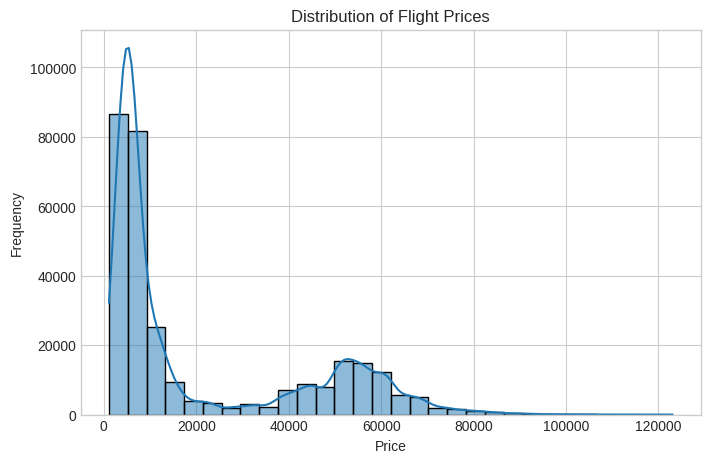

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["price"], kde=True, bins=30)

plt.title("Distribution of Flight Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

## Question 12

**Compute the mean, median and standard deviation of ticket prices. What do these statistics reveal about the distribution?**

In [ ]:
print("Mean Price :", df["price"].mean())
print("Median Price :", df["price"].median())
print("Standard Deviation :", df["price"].std())

Mean Price : 20889.660523133203
Median Price : 7425.0
Standard Deviation : 22697.767366075885


## Question 13

**Draw a boxplot of ticket prices. Identify possible outliers and explain why they might exist in airline pricing.**

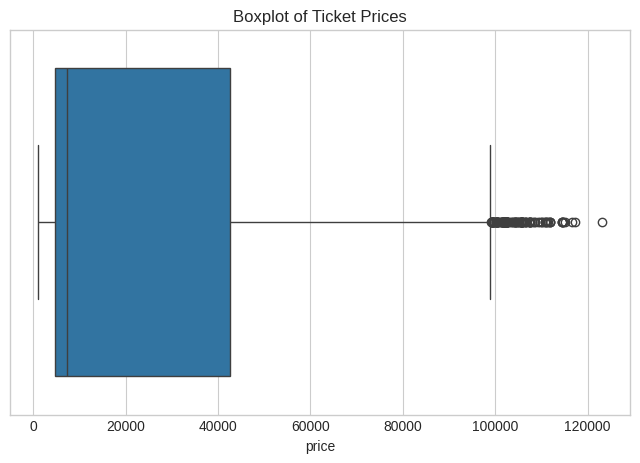

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["price"])

plt.title("Boxplot of Ticket Prices")

plt.show()

## Question 14

**Calculate the first quartile (Q1), median (Q2), third quartile (Q3) and interquartile range (IQR) of ticket prices.**

In [ ]:
Q1 = df["price"].quantile(0.25)
Q2 = df["price"].median()
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

print("Q1 :", Q1)
print("Median (Q2) :", Q2)
print("Q3 :", Q3)
print("IQR :", IQR)

Q1 : 4783.0
Median (Q2) : 7425.0
Q3 : 42521.0
IQR : 37738.0


## Question 15

**Classify ticket prices into Low, Medium and High using quartiles. How many flights fall into each category?**

In [ ]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

def price_category(price):
    if price <= Q1:
        return "Low"
    elif price <= Q3:
        return "Medium"
    else:
        return "High"

df["Price_Category"] = df["price"].apply(price_category)

print(df["Price_Category"].value_counts())

Price_Category
Medium    150701
Low        75073
High       74379
Name: count, dtype: int64


## Question 16

**Plot the distribution of flight duration. Is the distribution symmetric or skewed?**

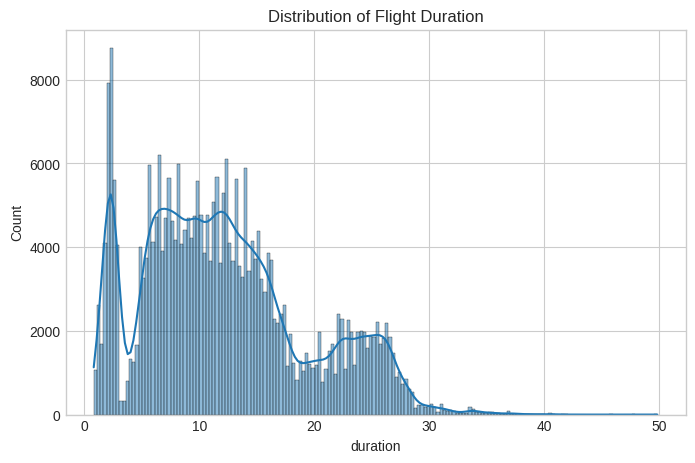

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["duration"], kde=True)

plt.title("Distribution of Flight Duration")

plt.show()

## Question 17

**Plot the distribution of Days Left. Are bookings concentrated close to departure or spread uniformly?**

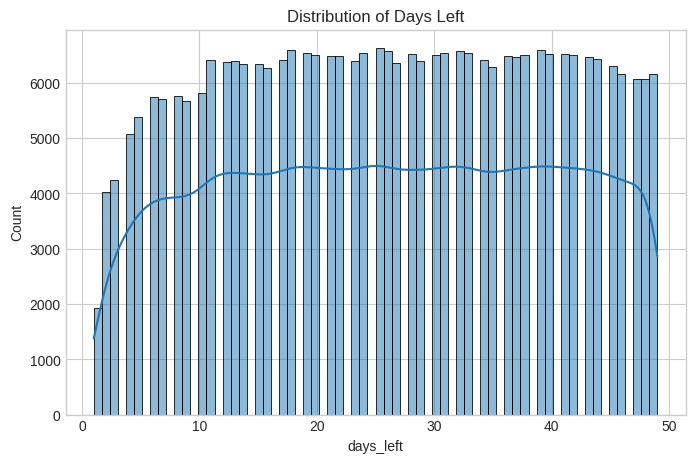

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["days_left"], kde=True)

plt.title("Distribution of Days Left")

plt.show()

## Question 18

**Compute skewness and kurtosis for Price, Duration and Days Left. Interpret the results.**

In [ ]:
columns = ["price", "duration", "days_left"]

for col in columns:
    print(f"\n{col.upper()}")
    print("Skewness :", df[col].skew())
    print("Kurtosis :", df[col].kurt())


PRICE
Skewness : 1.0613772532064343
Kurtosis : -0.3962927186960772

DURATION
Skewness : 0.6028991297746271
Kurtosis : -0.2689959580522556

DAYS_LEFT
Skewness : -0.035464349550665804
Kurtosis : -1.1562147251081518


## Question 19

**Calculate the coefficient of variation (CV) for Price and Duration. Which variable shows greater relative variability?**

In [ ]:
price_cv = (df["price"].std() / df["price"].mean()) * 100
duration_cv = (df["duration"].std() / df["duration"].mean()) * 100

print("Price CV :", price_cv)
print("Duration CV :", duration_cv)

Price CV : 108.65551089707937
Duration CV : 58.84939849405503


## Question 20

**Compare the distributions of Price and Duration using side-by-side boxplots.**

/tmp/ipykernel_1032/2421927255.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([df["price"], df["duration"]], labels=["Price", "Duration"])


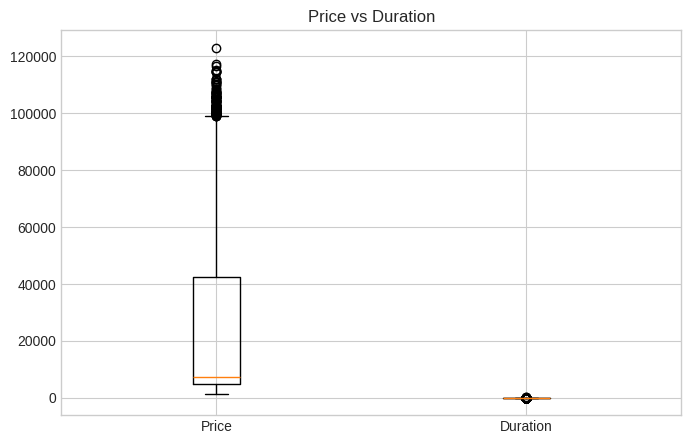

In [ ]:
plt.figure(figsize=(8,5))

plt.boxplot([df["price"], df["duration"]], labels=["Price", "Duration"])

plt.title("Price vs Duration")

plt.show()

# Section C – Airline-wise fare analysis

**Objective:** Compare pricing behaviour across different airline operators.

## Question 21

**Calculate the mean, median, minimum and maximum fare for every airline. Which airline has the highest median fare?**

In [ ]:
airline_stats = df.groupby("airline")["price"].agg(["mean", "median", "min", "max"])

print(airline_stats)

print("\nAirline with Highest Median Fare:")
print(airline_stats["median"].idxmax())

                   mean   median   min     max
airline                                       
AirAsia     4091.072742   3276.0  1105   31917
Air_India  23507.019112  11520.0  1526   90970
GO_FIRST    5652.007595   5336.0  1105   32803
Indigo      5324.216303   4453.0  1105   31952
SpiceJet    6179.278881   5654.0  1106   34158
Vistara    30396.536302  15543.0  1714  123071

Airline with Highest Median Fare:
Vistara


/tmp/ipykernel_1032/3763557355.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  airline_stats = df.groupby("airline")["price"].agg(["mean", "median", "min", "max"])


## Question 22

**Plot airline-wise fare distributions using boxplots. Which airline has the largest fare variation?**

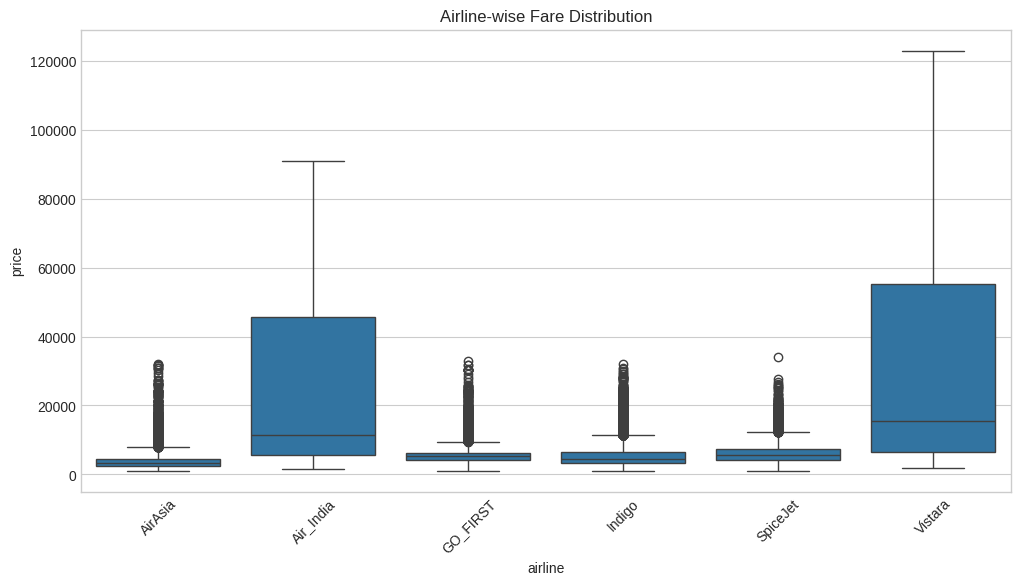

In [ ]:
plt.figure(figsize=(12,6))

sns.boxplot(x="airline", y="price", data=df)

plt.xticks(rotation=45)
plt.title("Airline-wise Fare Distribution")

plt.show()

## Question 23

**Rank airlines based on median ticket price. Does the ranking change when airlines are ranked using mean price?**

In [ ]:
median_rank = df.groupby("airline")["price"].median().sort_values(ascending=False)

mean_rank = df.groupby("airline")["price"].mean().sort_values(ascending=False)

print("Ranking by Median Fare")
print(median_rank)

print("\nRanking by Mean Fare")
print(mean_rank)

Ranking by Median Fare
airline
Vistara      15543.0
Air_India    11520.0
SpiceJet      5654.0
GO_FIRST      5336.0
Indigo        4453.0
AirAsia       3276.0
Name: price, dtype: float64

Ranking by Mean Fare
airline
Vistara      30396.536302
Air_India    23507.019112
SpiceJet      6179.278881
GO_FIRST      5652.007595
Indigo        5324.216303
AirAsia       4091.072742
Name: price, dtype: float64


/tmp/ipykernel_1032/498620391.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  median_rank = df.groupby("airline")["price"].median().sort_values(ascending=False)
/tmp/ipykernel_1032/498620391.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_rank = df.groupby("airline")["price"].mean().sort_values(ascending=False)


## Question 24

**Calculate the number of flights operated by each airline in the dataset. Is the airline with the highest number of records also the cheapest?**

In [ ]:
flight_counts = df["airline"].value_counts()

print("Flights Operated by Each Airline")
print(flight_counts)

print("\nAverage Fare")
print(df.groupby("airline")["price"].mean().sort_values())

Flights Operated by Each Airline
airline
Vistara      127859
Air_India     80892
Indigo        43120
GO_FIRST      23173
AirAsia       16098
SpiceJet       9011
Name: count, dtype: int64

Average Fare
airline
AirAsia       4091.072742
Indigo        5324.216303
GO_FIRST      5652.007595
SpiceJet      6179.278881
Air_India    23507.019112
Vistara      30396.536302
Name: price, dtype: float64


/tmp/ipykernel_1032/2673492856.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby("airline")["price"].mean().sort_values())


## Question 25

**Compare the distribution of Economy and Business fares for every airline. Does the class-wise fare gap differ across airlines?**

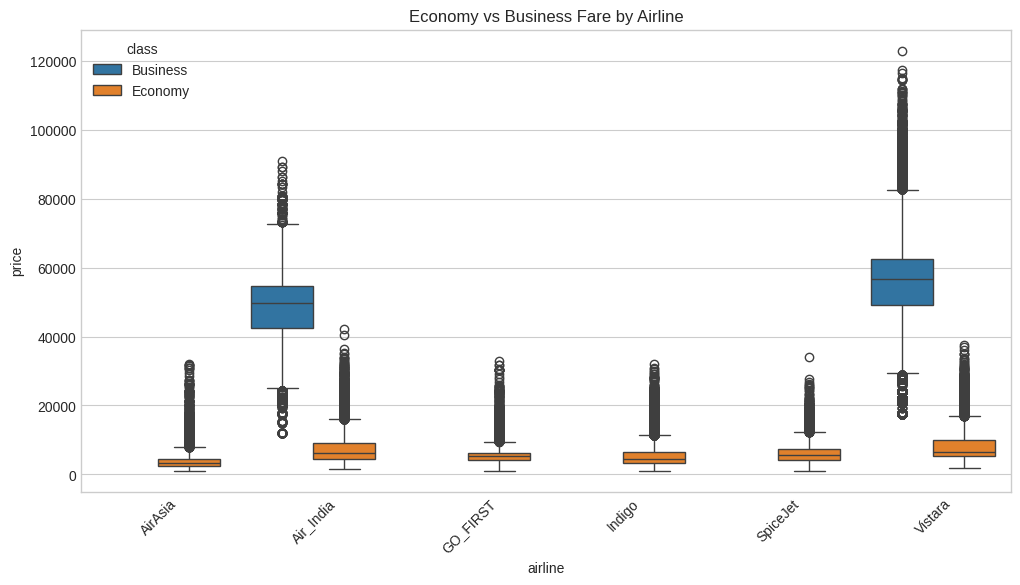

In [ ]:
plt.figure(figsize=(12,6))

sns.boxplot(x="airline", y="price", hue="class", data=df)

plt.xticks(rotation=45)

plt.title("Economy vs Business Fare by Airline")

plt.show()

## Question 26

**Identify the cheapest and most expensive airline for each source–destination combination. Make sure to compare only routes with sufficient observations.**

In [ ]:
route_airline = df.groupby(
    ["source_city", "destination_city", "airline"]
)["price"].mean().reset_index()

print(route_airline.sort_values("price"))

    source_city destination_city    airline        price
56      Chennai        Hyderabad   GO_FIRST  1613.105263
36      Chennai        Bangalore    AirAsia  1914.760870
116   Hyderabad          Chennai   GO_FIRST  1942.263158
54      Chennai        Hyderabad    AirAsia  2053.182540
6     Bangalore          Chennai    AirAsia  2073.043478
..          ...              ...        ...          ...
211      Mumbai           Mumbai  Air_India          NaN
212      Mumbai           Mumbai   GO_FIRST          NaN
213      Mumbai           Mumbai     Indigo          NaN
214      Mumbai           Mumbai   SpiceJet          NaN
215      Mumbai           Mumbai    Vistara          NaN

[216 rows x 4 columns]


/tmp/ipykernel_1032/3642869984.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  route_airline = df.groupby(


## Question 27

**Calculate the percentage of each airline's records that fall below the overall median fare. Which airlines have the highest proportion of relatively inexpensive tickets?**

In [ ]:
overall_median = df["price"].median()

cheap_percentage = (
    df.assign(Cheap=df["price"] < overall_median)
      .groupby("airline")["Cheap"]
      .mean() * 100
)

print(cheap_percentage.sort_values(ascending=False))

airline
AirAsia      91.172816
GO_FIRST     87.696889
Indigo       81.145640
SpiceJet     75.785151
Air_India    39.701083
Vistara      31.738869
Name: Cheap, dtype: float64


/tmp/ipykernel_1032/1015605800.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("airline")["Cheap"]


## Question 28

**Investigate whether an airline's fare distribution changes with the number of stops. For example, compare non-stop and one-stop fares within the same airline.**

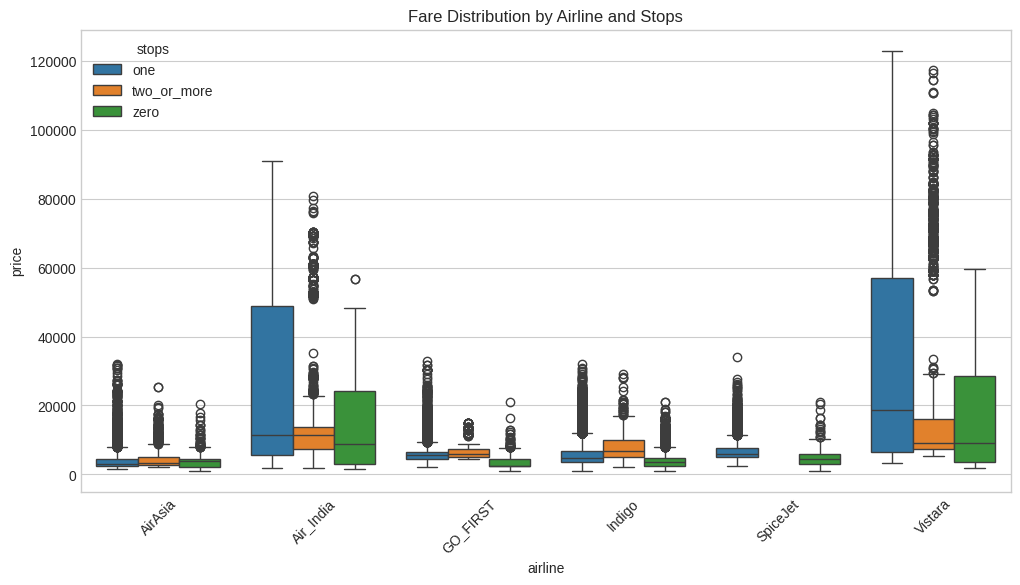

In [ ]:
plt.figure(figsize=(12,6))

sns.boxplot(
    x="airline",
    y="price",
    hue="stops",
    data=df
)

plt.xticks(rotation=45)

plt.title("Fare Distribution by Airline and Stops")

plt.show()

# Section D – Route, source and destination analysis

**Objective:** Understand geographical variations in Indian domestic flight prices.

## Question 29

**Find the number of unique source–destination combinations. How many observations exist for each route?**

In [ ]:
route_counts = (
    df.groupby(["source_city", "destination_city"])
      .size()
      .reset_index(name="Observations")
)

print("Number of Unique Routes:", len(route_counts))
route_counts

Number of Unique Routes: 36


/tmp/ipykernel_1032/1219870204.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["source_city", "destination_city"])


,source_city,destination_city,Observations
0,Bangalore,Bangalore,0
1,Bangalore,Chennai,6410
2,Bangalore,Delhi,13756
3,Bangalore,Hyderabad,8928
4,Bangalore,Kolkata,10028
5,Bangalore,Mumbai,12939
6,Chennai,Bangalore,6493
7,Chennai,Chennai,0
8,Chennai,Delhi,9783
9,Chennai,Hyderabad,6103


## Question 30

**Create a route column by combining source and destination, for example:**

In [ ]:
# Question 30
# Create a Route column by combining Source and Destination cities

df["Route"] = (
    df["source_city"].astype(str)
    + " -> "
    + df["destination_city"].astype(str)
)

print("First 10 Routes:")
display(df[["source_city", "destination_city", "Route"]].head(10))

First 10 Routes:


,source_city,destination_city,Route
0,Delhi,Mumbai,Delhi -> Mumbai
1,Delhi,Mumbai,Delhi -> Mumbai
2,Delhi,Mumbai,Delhi -> Mumbai
3,Delhi,Mumbai,Delhi -> Mumbai
4,Delhi,Mumbai,Delhi -> Mumbai
5,Delhi,Mumbai,Delhi -> Mumbai
6,Delhi,Mumbai,Delhi -> Mumbai
7,Delhi,Mumbai,Delhi -> Mumbai
8,Delhi,Mumbai,Delhi -> Mumbai
9,Delhi,Mumbai,Delhi -> Mumbai


## Question 31

**Calculate the average and median fare for every route. Which routes have the highest and lowest median prices?**

In [ ]:
# Calculate average and median fare for each route

route_stats = (
    df.groupby("Route")["price"]
      .agg(["mean", "median", "count"])
      .sort_values(by="median", ascending=False)
)

print("Route-wise Fare Statistics")
display(route_stats)

print("\nTop 10 Routes with Highest Median Fare")
display(route_stats.head(10))

print("\nTop 10 Routes with Lowest Median Fare")
display(route_stats.tail(10))

Route-wise Fare Statistics


,mean,median,count
Route,,,
Chennai -> Bangalore,25081.850454,10469.0,6493
Bangalore -> Chennai,23321.850078,9241.0,6410
Kolkata -> Chennai,23660.361040,8589.0,6653
Kolkata -> Hyderabad,21500.011397,8467.0,7897
Chennai -> Kolkata,22669.932407,8394.0,6983
Chennai -> Mumbai,22765.849647,8233.0,9338
Mumbai -> Chennai,22781.899112,8148.0,10130
Bangalore -> Kolkata,23500.061229,8112.0,10028
Kolkata -> Bangalore,22744.808428,8111.0,9824



Top 10 Routes with Highest Median Fare


,mean,median,count
Route,,,
Chennai -> Bangalore,25081.850454,10469.0,6493
Bangalore -> Chennai,23321.850078,9241.0,6410
Kolkata -> Chennai,23660.361040,8589.0,6653
Kolkata -> Hyderabad,21500.011397,8467.0,7897
Chennai -> Kolkata,22669.932407,8394.0,6983
Chennai -> Mumbai,22765.849647,8233.0,9338
Mumbai -> Chennai,22781.899112,8148.0,10130
Bangalore -> Kolkata,23500.061229,8112.0,10028
Kolkata -> Bangalore,22744.808428,8111.0,9824



Top 10 Routes with Lowest Median Fare


,mean,median,count
Route,,,
Bangalore -> Delhi,17723.313972,7164.0,13756
Bangalore -> Mumbai,23128.618672,7113.0,12939
Hyderabad -> Bangalore,21347.177998,7091.0,7854
Delhi -> Kolkata,20566.409418,7084.0,11934
Kolkata -> Delhi,19422.354559,6723.0,10506
Delhi -> Bangalore,17880.216315,6642.0,14012
Hyderabad -> Mumbai,20080.865759,6633.0,10064
Mumbai -> Delhi,18725.320008,6300.0,14809
Hyderabad -> Delhi,17243.945685,6138.0,8506


## Question 32

**Calculate the average and median fare for every route. Which routes have the highest and lowest median prices?**

In [ ]:
route_stats = (
    df.groupby("Route")["price"]
      .agg(["mean", "median"])
      .sort_values("median", ascending=False)
)

print("Route-wise Average and Median Fare")
display(route_stats)

print("\nHighest Median Fare Routes")
display(route_stats.head())

print("\nLowest Median Fare Routes")
display(route_stats.tail())

Route-wise Average and Median Fare


,mean,median
Route,,
Chennai -> Bangalore,25081.850454,10469.0
Bangalore -> Chennai,23321.850078,9241.0
Kolkata -> Chennai,23660.361040,8589.0
Kolkata -> Hyderabad,21500.011397,8467.0
Chennai -> Kolkata,22669.932407,8394.0
Chennai -> Mumbai,22765.849647,8233.0
Mumbai -> Chennai,22781.899112,8148.0
Bangalore -> Kolkata,23500.061229,8112.0
Kolkata -> Bangalore,22744.808428,8111.0



Highest Median Fare Routes


,mean,median
Route,,
Chennai -> Bangalore,25081.850454,10469.0
Bangalore -> Chennai,23321.850078,9241.0
Kolkata -> Chennai,23660.361040,8589.0
Kolkata -> Hyderabad,21500.011397,8467.0
Chennai -> Kolkata,22669.932407,8394.0



Lowest Median Fare Routes


,mean,median
Route,,
Delhi -> Bangalore,17880.216315,6642.0
Hyderabad -> Mumbai,20080.865759,6633.0
Mumbai -> Delhi,18725.320008,6300.0
Hyderabad -> Delhi,17243.945685,6138.0
Delhi -> Hyderabad,17347.288379,6109.0


## Question 33

**Are fares from Delhi to Mumbai similar to fares from Mumbai to Delhi? Compare both directions.**

In [ ]:
delhi_mumbai = df[
    (df["source_city"] == "Delhi") &
    (df["destination_city"] == "Mumbai")
]

mumbai_delhi = df[
    (df["source_city"] == "Mumbai") &
    (df["destination_city"] == "Delhi")
]

print("Delhi → Mumbai")
display(delhi_mumbai["price"].describe())

print("\nMumbai → Delhi")
display(mumbai_delhi["price"].describe())

Delhi → Mumbai


,price
count,15289.000000
mean,19355.829812
std,19777.253580
min,2281.000000
25%,4381.000000
50%,7262.000000
75%,36712.000000
max,95657.000000



Mumbai → Delhi


,price
count,14809.000000
mean,18725.320008
std,19493.523862
min,2336.000000
25%,4221.000000
50%,6300.000000
75%,36565.000000
max,111437.000000


## Question 34

**Create a pivot table with source cities as rows, destination cities as columns and median ticket prices as values.**

In [ ]:
pivot = df.pivot_table(
    values="price",
    index="source_city",
    columns="destination_city",
    aggfunc="median"
)

display(pivot)

/tmp/ipykernel_1032/1285360858.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = df.pivot_table(


destination_city,Bangalore,Chennai,Delhi,Hyderabad,Kolkata,Mumbai
source_city,,,,,,
Bangalore,NaN,9241.0,7164.0,7813.0,8112.0,7113.0
Chennai,10469.0,NaN,7352.0,7373.0,8394.0,8233.0
Delhi,6642.0,7425.0,NaN,6109.0,7084.0,7262.0
Hyderabad,7091.0,7702.0,6138.0,NaN,7767.0,6633.0
Kolkata,8111.0,8589.0,6723.0,8467.0,NaN,7958.0
Mumbai,7192.0,8148.0,6300.0,7584.0,7518.0,NaN


## Question 35

**Plot a heatmap of median ticket prices for all source-destination combinations. Which city pairs have relatively high or low fares?**

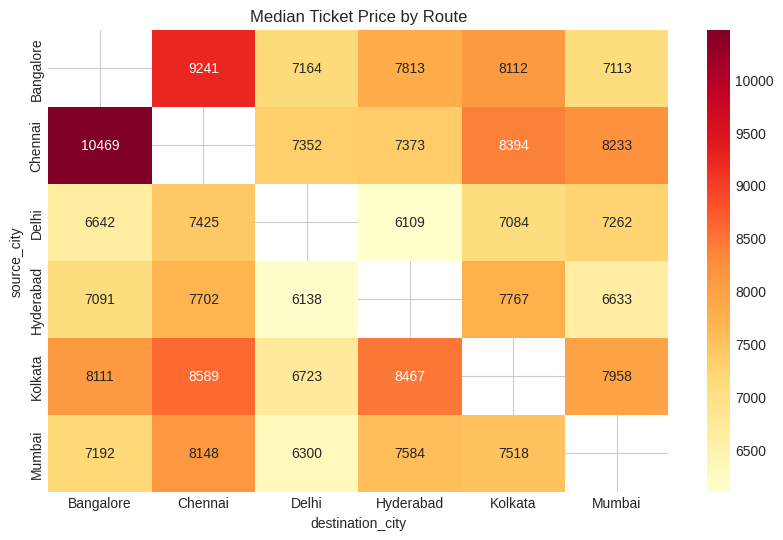

In [ ]:
plt.figure(figsize=(10,6))

sns.heatmap(
    pivot,
    annot=True,
    cmap="YlOrRd",
    fmt=".0f"
)

plt.title("Median Ticket Price by Route")
plt.show()

## Question 36

**Compare the number of available flights against median fare for each route. Do routes with more observations tend to have lower prices?**

,Flights,Median_Fare
Route,,
Bangalore -> Chennai,6410,9241.0
Bangalore -> Delhi,13756,7164.0
Bangalore -> Hyderabad,8928,7813.0
Bangalore -> Kolkata,10028,8112.0
Bangalore -> Mumbai,12939,7113.0
Chennai -> Bangalore,6493,10469.0
Chennai -> Delhi,9783,7352.0
Chennai -> Hyderabad,6103,7373.0
Chennai -> Kolkata,6983,8394.0


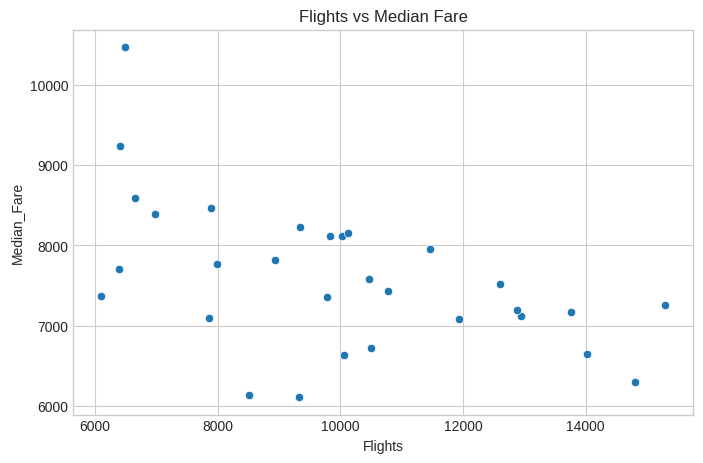

In [ ]:
route_analysis = df.groupby("Route").agg(
    Flights=("price", "count"),
    Median_Fare=("price", "median")
)

display(route_analysis)

plt.figure(figsize=(8,5))

sns.scatterplot(
    data=route_analysis,
    x="Flights",
    y="Median_Fare"
)

plt.title("Flights vs Median Fare")
plt.show()

## Question 37

**For every route, identify the cheapest airline and compare its median price against the route-wide median.**

In [ ]:
route_median = df.groupby("Route")["price"].median()

cheapest = (
    df.groupby(["Route", "airline"])["price"]
      .median()
      .reset_index()
)

cheapest = cheapest.loc[
    cheapest.groupby("Route")["price"].idxmin()
]

cheapest["Route_Median"] = cheapest["Route"].map(route_median)

display(cheapest)

/tmp/ipykernel_1032/3022143113.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["Route", "airline"])["price"]


,Route,airline,price,Route_Median
0,Bangalore -> Chennai,AirAsia,1715.0,9241.0
6,Bangalore -> Delhi,AirAsia,3467.0,7164.0
12,Bangalore -> Hyderabad,AirAsia,1714.0,7813.0
18,Bangalore -> Kolkata,AirAsia,3393.0,8112.0
24,Bangalore -> Mumbai,AirAsia,2203.0,7113.0
30,Chennai -> Bangalore,AirAsia,1548.0,10469.0
36,Chennai -> Delhi,AirAsia,2477.0,7352.0
44,Chennai -> Hyderabad,GO_FIRST,1105.0,7373.0
48,Chennai -> Kolkata,AirAsia,2361.0,8394.0
54,Chennai -> Mumbai,AirAsia,1830.0,8233.0


## Question 38

**Investigate whether the effect of stops on price is different for different routes.**

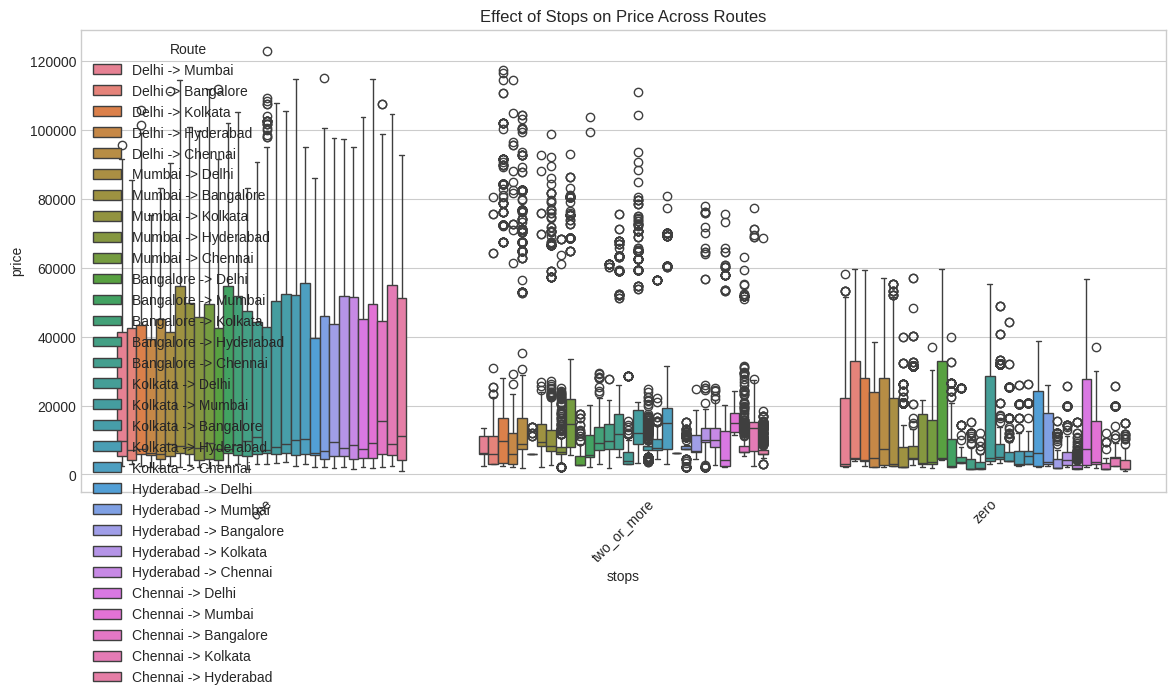

In [ ]:
plt.figure(figsize=(14,6))

sns.boxplot(
    data=df,
    x="stops",
    y="price",
    hue="Route"
)

plt.title("Effect of Stops on Price Across Routes")
plt.xticks(rotation=45)

plt.show()

# Section E – Booking window and Days Left analysis

Objective: Investigate the relationship between advance booking and ticket price.

This is one of the most important sections of the assignment.

## Question 38

Plot a scatter plot of Days Left against Price. Does the relationship appear linear, nonlinear or highly scattered?

,days_left,mean,median
0,1,21591.867151,15163.0
1,2,30211.299801,18017.5
2,3,28976.083569,16333.0
3,4,25730.905653,13054.0
4,5,26679.773368,13054.0
5,6,24856.493902,12417.5
6,7,25588.367351,12990.0
7,8,24895.883995,12658.0
8,9,25726.246072,13947.0
9,10,25572.819134,13303.0


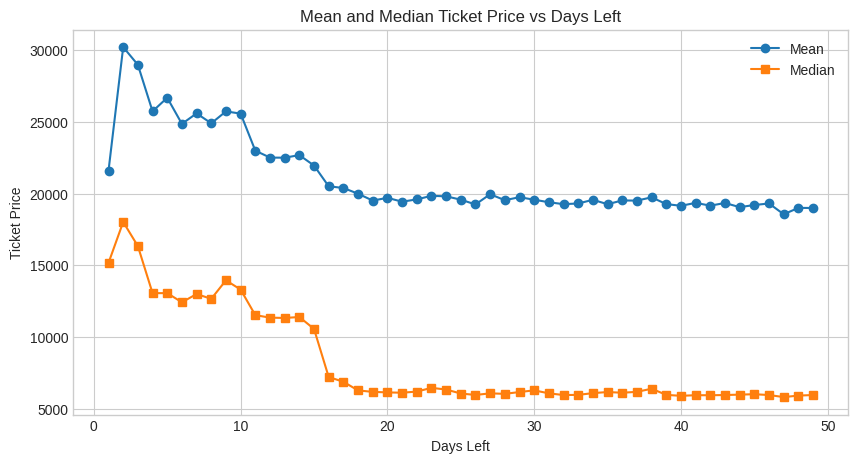

In [ ]:
days_stats = (
    df.groupby("days_left")["price"]
      .agg(["mean", "median"])
      .reset_index()
)

display(days_stats)

plt.figure(figsize=(10,5))

plt.plot(days_stats["days_left"], days_stats["mean"], marker="o", label="Mean")
plt.plot(days_stats["days_left"], days_stats["median"], marker="s", label="Median")

plt.xlabel("Days Left")
plt.ylabel("Ticket Price")
plt.title("Mean and Median Ticket Price vs Days Left")
plt.legend()

plt.show()

## Question 40

**Divide booking windows into groups:**

- 0–3 days
- 4–7 days
- 8–15 days
- 16–30 days
- 31–45 days
- 46–60 days
- More than 60 days, if present

**Calculate the average and median fare in each group.**

In [ ]:
bins = [-1, 3, 7, 15, 30, 45, 60, float("inf")]
labels = [
    "0-3 days",
    "4-7 days",
    "8-15 days",
    "16-30 days",
    "31-45 days",
    "46-60 days",
    "More than 60 days"
]

df["Booking_Window"] = pd.cut(
    df["days_left"],
    bins=bins,
    labels=labels
)

booking_stats = (
    df.groupby("Booking_Window")["price"]
      .agg(["mean", "median"])
)

display(booking_stats)

/tmp/ipykernel_1032/3333556955.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("Booking_Window")["price"]


,mean,median
Booking_Window,,
0-3 days,28068.681894,16572.0
4-7 days,25698.242059,12978.0
8-15 days,23534.110876,11893.0
16-30 days,19754.193214,6228.5
31-45 days,19335.684475,6056.0
46-60 days,18963.825600,5896.0
More than 60 days,NaN,NaN


## Question 41

**Which booking window has the highest median ticket price? Which has the lowest?**

In [ ]:
booking_stats = booking_stats.sort_values("median", ascending=False)

print("Booking Window with Highest Median Fare")
display(booking_stats.head(1))

print("\nBooking Window with Lowest Median Fare")
display(booking_stats.tail(1))

Booking Window with Highest Median Fare


,mean,median
Booking_Window,,
0-3 days,28068.681894,16572.0



Booking Window with Lowest Median Fare


,mean,median
Booking_Window,,
More than 60 days,NaN,NaN


## Question 42

**Does the relationship between Days Left and Price differ between Economy and Business class?**

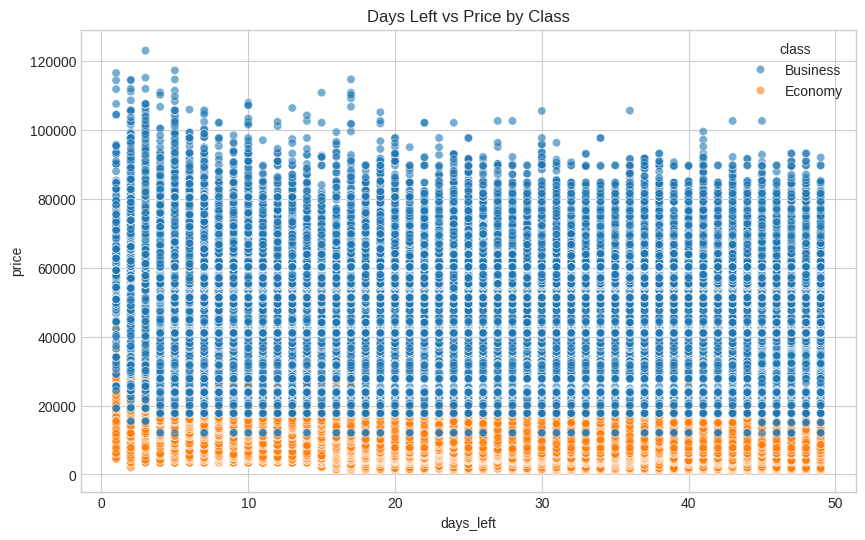

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="days_left",
    y="price",
    hue="class",
    alpha=0.6
)

plt.title("Days Left vs Price by Class")

plt.show()

## Question 43

**Does the booking-window effect differ between airlines? Create a separate plot for the major airlines.**

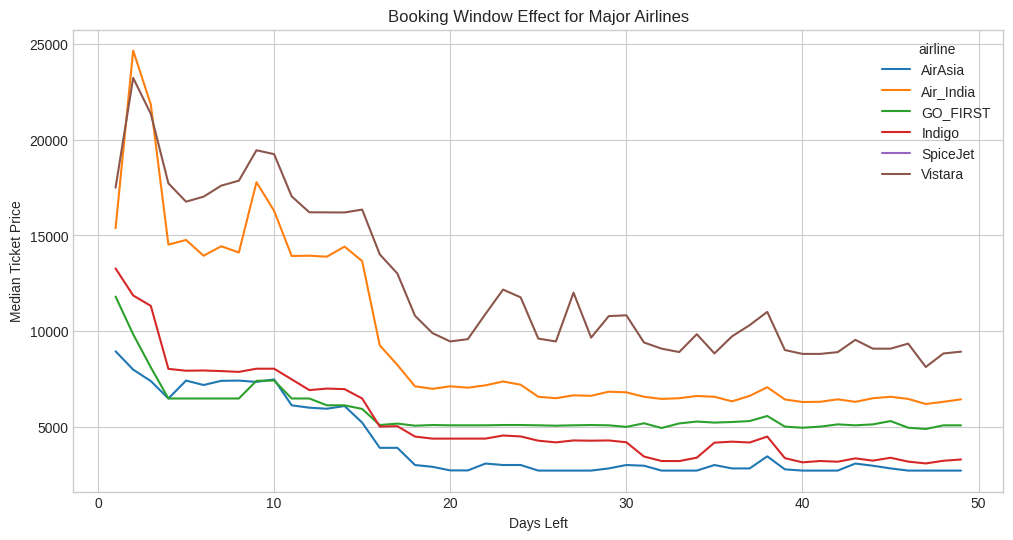

In [ ]:
major_airlines = df["airline"].value_counts().head(5).index

plt.figure(figsize=(12,6))

sns.lineplot(
    data=df[df["airline"].isin(major_airlines)],
    x="days_left",
    y="price",
    hue="airline",
    estimator="median",
    errorbar=None
)

plt.title("Booking Window Effect for Major Airlines")
plt.xlabel("Days Left")
plt.ylabel("Median Ticket Price")

plt.show()

## Question 44

**Compare the booking-window pattern for non-stop and connecting flights.**

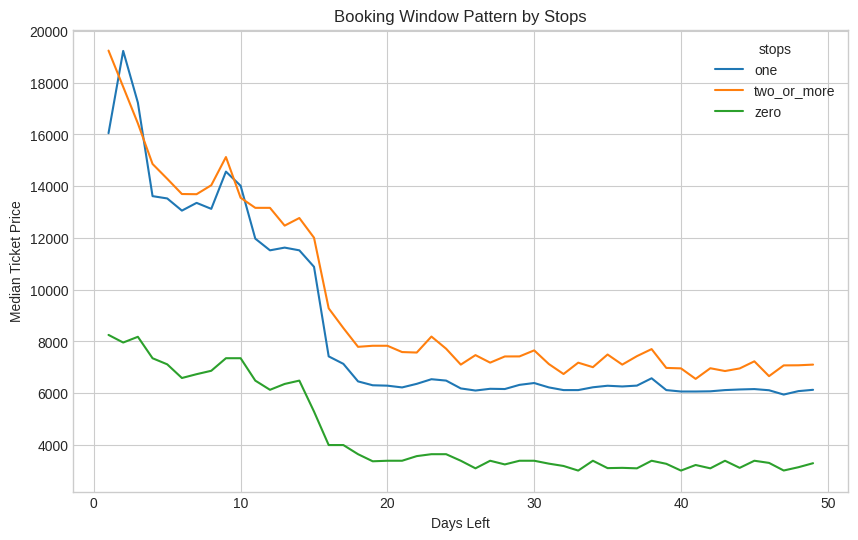

In [ ]:
plt.figure(figsize=(10,6))

sns.lineplot(
    data=df,
    x="days_left",
    y="price",
    hue="stops",
    estimator="median",
    errorbar=None
)

plt.title("Booking Window Pattern by Stops")
plt.xlabel("Days Left")
plt.ylabel("Median Ticket Price")

plt.show()

## Question 45

**Select a few high-volume routes and investigate their booking-window trends independently. Are the trends consistent across routes?**

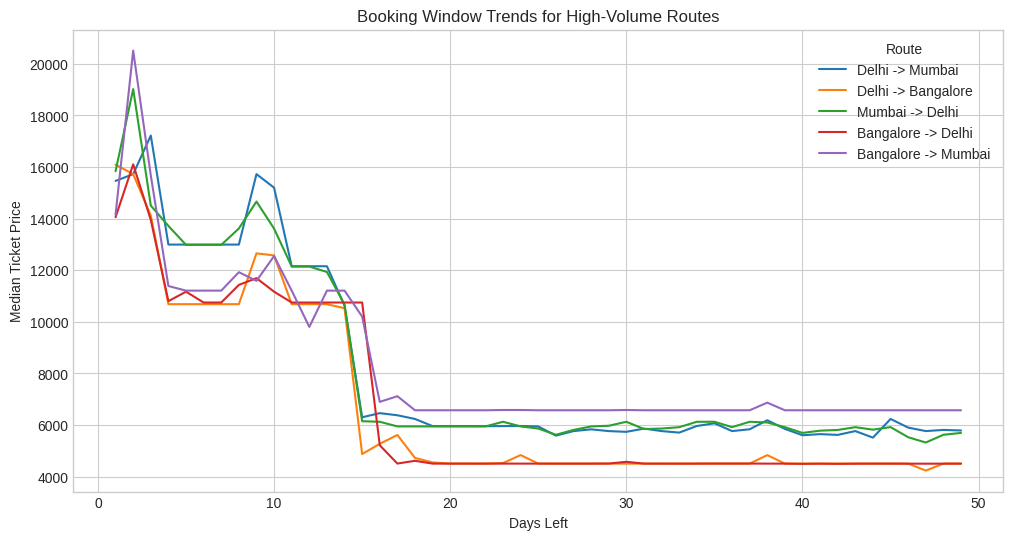

In [ ]:
top_routes = df["Route"].value_counts().head(5).index

route_df = df[df["Route"].isin(top_routes)]

plt.figure(figsize=(12,6))

sns.lineplot(
    data=route_df,
    x="days_left",
    y="price",
    hue="Route",
    estimator="median",
    errorbar=None
)

plt.title("Booking Window Trends for High-Volume Routes")
plt.xlabel("Days Left")
plt.ylabel("Median Ticket Price")

plt.show()

## Question 46

**Calculate the percentage change in median price between the earliest and latest booking-window groups. State clearly which groups are being compared.**

In [ ]:
booking_median = (
    df.groupby("Booking_Window")["price"]
      .median()
      .reindex(labels)
)

display(booking_median)

earliest = booking_median["More than 60 days"]
latest = booking_median["0-3 days"]

percentage_change = ((latest - earliest) / earliest) * 100

print(f"Earliest Booking Window : More than 60 days")
print(f"Latest Booking Window   : 0-3 days")
print(f"Percentage Change in Median Price : {percentage_change:.2f}%")

/tmp/ipykernel_1032/3220477233.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("Booking_Window")["price"]


,price
Booking_Window,
0-3 days,16572.0
4-7 days,12978.0
8-15 days,11893.0
16-30 days,6228.5
31-45 days,6056.0
46-60 days,5896.0
More than 60 days,NaN


Earliest Booking Window : More than 60 days
Latest Booking Window   : 0-3 days
Percentage Change in Median Price : nan%


# Section F – Flight duration, stops and time-of-day analysis

**Objective:** Explore how flight logistics and timing relate to ticket prices.

## Question 47

**Does flight duration have a relationship with ticket price? Create a scatter plot and calculate Pearson and Spearman correlations.**

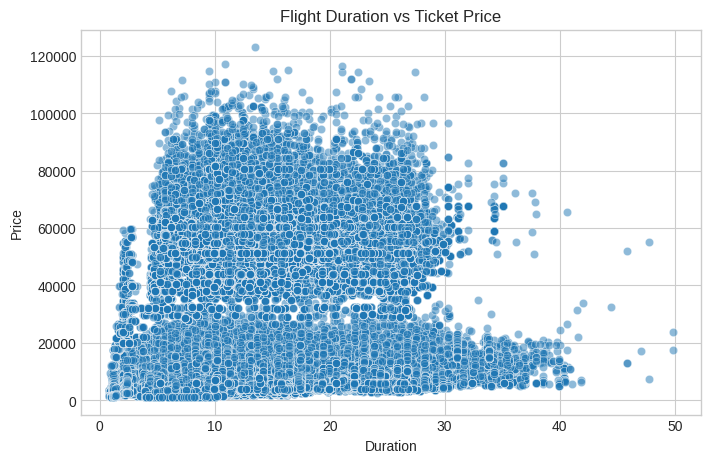

Pearson Correlation : 0.20422236784542702
Spearman Correlation : 0.3188412266334599


In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="duration",
    y="price",
    alpha=0.5
)

plt.title("Flight Duration vs Ticket Price")
plt.xlabel("Duration")
plt.ylabel("Price")

plt.show()

pearson_corr = df["duration"].corr(df["price"], method="pearson")
spearman_corr = df["duration"].corr(df["price"], method="spearman")

print("Pearson Correlation :", pearson_corr)
print("Spearman Correlation :", spearman_corr)

## Question 48

**Compare median prices for non-stop, one-stop, two-stop and other available stop categories.**

/tmp/ipykernel_1032/3817632605.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("stops")["price"]


,price
stops,
two_or_more,8307.0
one,7959.0
zero,4499.0


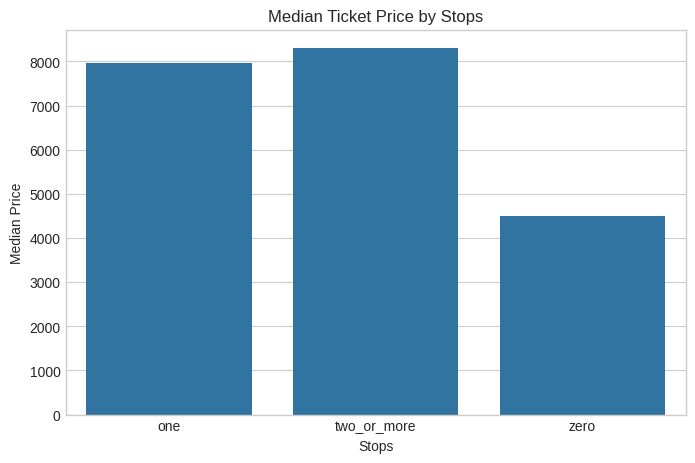

In [ ]:
median_stop_price = (
    df.groupby("stops")["price"]
      .median()
      .sort_values(ascending=False)
)

display(median_stop_price)

plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x="stops",
    y="price",
    estimator=np.median,
    errorbar=None
)

plt.title("Median Ticket Price by Stops")
plt.xlabel("Stops")
plt.ylabel("Median Price")

plt.show()

## Question 49

**Are longer flights more expensive within the same source-destination route? Compare duration and price after controlling for route.**

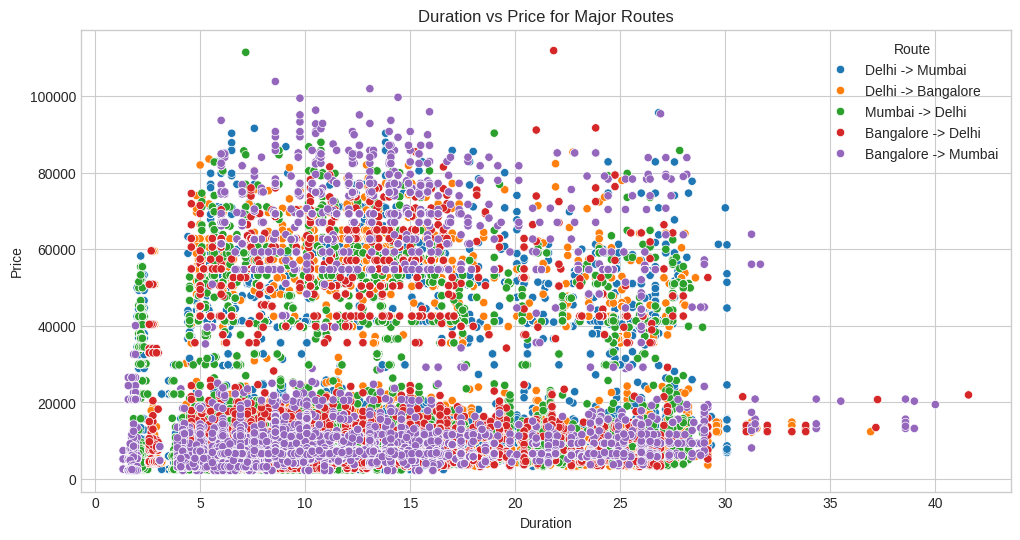

In [ ]:
top_routes = df["Route"].value_counts().head(5).index

route_df = df[df["Route"].isin(top_routes)]

plt.figure(figsize=(12,6))

sns.scatterplot(
    data=route_df,
    x="duration",
    y="price",
    hue="Route"
)

plt.title("Duration vs Price for Major Routes")
plt.xlabel("Duration")
plt.ylabel("Price")

plt.show()

## Question 50

**Compare fare distributions across departure periods: early morning, morning, afternoon, evening and night. Which time category has the highest median fare?**

/tmp/ipykernel_1032/2591406483.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("departure_time")["price"]


,price
departure_time,
Morning,8112.0
Night,7813.0
Evening,7425.0
Early_Morning,7212.0
Afternoon,6663.0
Late_Night,4499.0


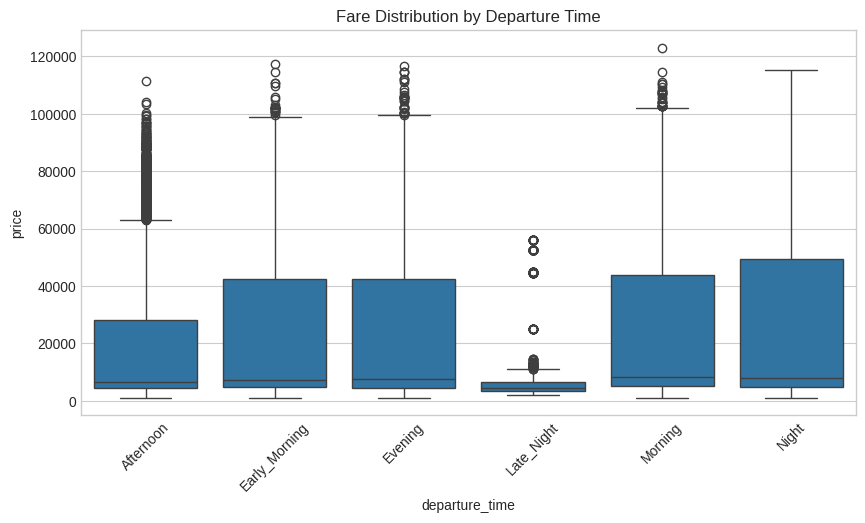

In [ ]:
departure_median = (
    df.groupby("departure_time")["price"]
      .median()
      .sort_values(ascending=False)
)

display(departure_median)

plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x="departure_time",
    y="price"
)

plt.title("Fare Distribution by Departure Time")
plt.xticks(rotation=45)

plt.show()

## Question 51

**Repeat the analysis for arrival time. Does arrival period show a similar pattern to departure period?**

/tmp/ipykernel_1032/3120435864.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("arrival_time")["price"]


,price
arrival_time,
Evening,8854.0
Morning,7687.0
Night,7584.0
Afternoon,6714.0
Early_Morning,5800.0
Late_Night,4867.0


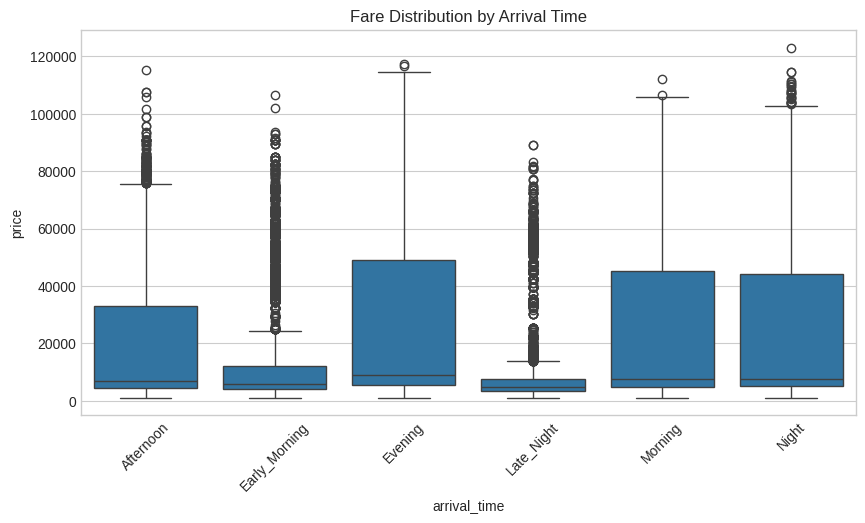

In [ ]:
arrival_median = (
    df.groupby("arrival_time")["price"]
      .median()
      .sort_values(ascending=False)
)

display(arrival_median)

plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x="arrival_time",
    y="price"
)

plt.title("Fare Distribution by Arrival Time")
plt.xticks(rotation=45)

plt.show()

## Question 52

**Does a longer duration necessarily mean more stops? Compare duration distribution across stop categories.**

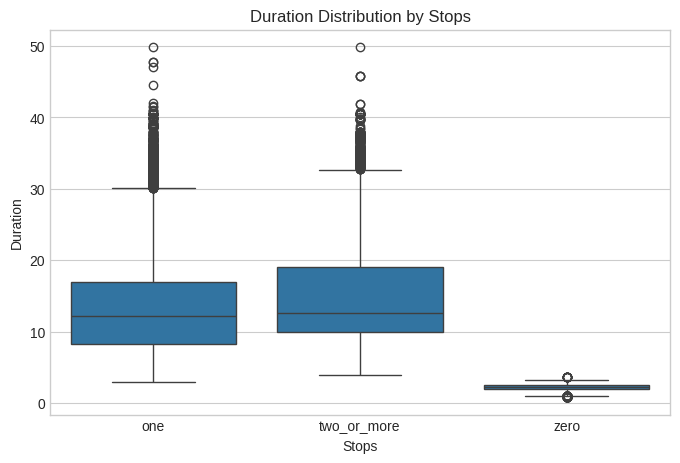

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="stops",
    y="duration"
)

plt.title("Duration Distribution by Stops")
plt.xlabel("Stops")
plt.ylabel("Duration")

plt.show()

## Question 53

**Which airlines offer the shortest median duration for each route? Are they also the most expensive?**

In [ ]:
route_airline = (
    df.groupby(["Route", "airline"])
      .agg(
          Median_Duration=("duration", "median"),
          Median_Price=("price", "median")
      )
      .reset_index()
)

shortest = route_airline.loc[
    route_airline.groupby("Route")["Median_Duration"].idxmin()
]

display(shortest)

/tmp/ipykernel_1032/2279169603.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["Route", "airline"])


,Route,airline,Median_Duration,Median_Price
0,Bangalore -> Chennai,AirAsia,1.00,1715.0
9,Bangalore -> Delhi,Indigo,5.92,4500.0
16,Bangalore -> Hyderabad,SpiceJet,1.08,4338.0
22,Bangalore -> Kolkata,SpiceJet,5.75,4814.0
27,Bangalore -> Mumbai,Indigo,5.17,4435.0
33,Chennai -> Bangalore,Indigo,1.08,1654.0
39,Chennai -> Delhi,Indigo,6.33,4071.0
44,Chennai -> Hyderabad,GO_FIRST,1.25,1105.0
52,Chennai -> Kolkata,SpiceJet,2.50,4620.0
56,Chennai -> Mumbai,GO_FIRST,1.92,3000.0


## Question 54

**Compare the relationship between duration and fare for Economy and Business class separately.**

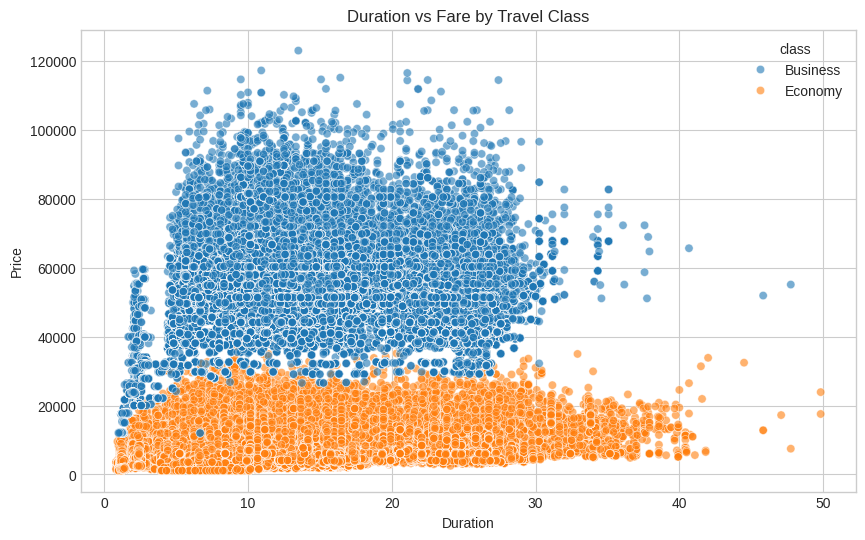

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="duration",
    y="price",
    hue="class",
    alpha=0.6
)

plt.title("Duration vs Fare by Travel Class")
plt.xlabel("Duration")
plt.ylabel("Price")

plt.show()

# 3. Consolidated Key Insights & Recommendations

| Analysis Vector | Observed Pattern | Strategic Action |
|-----------------|------------------|------------------|
| Booking Window | Significant fare surge within 0–3 days of departure. | Promote advance booking alerts at 16–30 day window. |
| Class Disparity | Business class shows a multi-fold price multiplier over Economy. | Target corporate accounts with customized business bundles. |
| Departure Timing | Peak morning and evening hours command premium pricing. | Highlight mid-day and off-peak options for budget travelers. |